In [1]:
from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download("https://github.com/AllenDowney/ThinkStats/raw/v3/nb/thinkstats.py")

In [2]:
try:
    import empiricaldist
except ImportError:
    %pip install empiricaldist

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thinkstats import decorate

In [4]:
from empiricaldist import FreqTab
ftab = FreqTab.from_seq([1,2,2,3,5])
ftab

,freqs
1,1
2,2
3,1
5,1


In [5]:
n = ftab.sum()
n

np.int64(5)

In [6]:
pmf = ftab/n
pmf

,probs
1,0.2
2,0.4
3,0.2
5,0.2


In [7]:
pmf.sum()

np.float64(1.0)

In [8]:
from empiricaldist import Pmf

pmf = Pmf.from_seq([1,2,2,3,5])
pmf

,probs
1,0.2
2,0.4
3,0.2
5,0.2


In [9]:
pmf.sum()

np.float64(1.0)

In [10]:
pmf[2]

np.float64(0.4)

In [11]:
pmf(2)

np.float64(0.4)

In [12]:
pmf[2] = 0.2
pmf(2)

np.float64(0.2)

In [13]:
pmf[2] += 0.3
pmf[2]

np.float64(0.5)

In [14]:
pmf[2] *=0.5
pmf[2]

np.float64(0.25)

In [15]:
pmf.sum()

np.float64(0.8500000000000001)

In [16]:
pmf.normalize()

np.float64(0.8500000000000001)

In [17]:
pmf.copy()

,probs
1,0.235294
2,0.294118
3,0.235294
5,0.235294


In [18]:
seq = [1, 2, 2, 3, 5]

n = len(seq)
mean = np.sum(seq) / n
mean

np.float64(2.6)

In [19]:
pmf = Pmf.from_seq(seq)

In [20]:
mean = np.sum(pmf.ps * pmf.qs)
mean

np.float64(2.6)

In [21]:
pmf.mean()

np.float64(2.6)

In [22]:
deviations = pmf.qs - mean

In [23]:
var = np.sum(pmf.ps * deviations**2)
var

np.float64(1.84)

In [24]:
pmf.var()

np.float64(1.84)

In [25]:
np.sqrt(var)

np.float64(1.3564659966250536)

In [26]:
pmf.std()

np.float64(1.3564659966250536)

In [27]:
pmf.mode()

np.int64(2)

In [28]:
ranges = pd.interval_range(start = 5, end = 50, freq = 5, closed = 'left')
ranges.name = 'class size'

data = pd.DataFrame(index=ranges)
data['count'] = [8,8,14,4,6,12,8,3,2]
data

,count
class size,
"[5, 10)",8
"[10, 15)",8
"[15, 20)",14
"[20, 25)",4
"[25, 30)",6
"[30, 35)",12
"[35, 40)",8
"[40, 45)",3
"[45, 50)",2


In [29]:
sizes = ranges.left + 2
sizes

Index([7, 12, 17, 22, 27, 32, 37, 42, 47], dtype='int64')

In [30]:
counts = data['count']
actual_pmf = Pmf(counts, sizes, name = 'actual')
actual_pmf.normalize()

np.int64(65)

In [31]:
actual_pmf.mean()

np.float64(23.692307692307693)

In [32]:
def bias(pmf, name):
    #multiply each probability by class size
    ps = pmf.ps * pmf.qs

    #mane a new PMF and normalize it
    new_pmf = Pmf(ps, pmf.qs, name=name)
    new_pmf.normalize()
    return new_pmf

In [33]:
observed_pmf = bias(actual_pmf, name = 'observed')

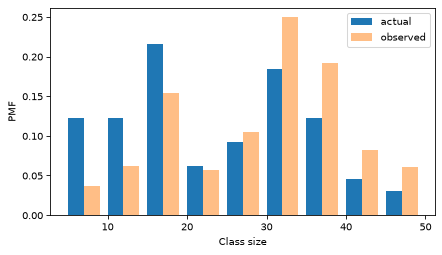

In [34]:
from thinkstats import two_bar_plots

two_bar_plots(actual_pmf, observed_pmf, width=2)
decorate(xlabel='Class size', ylabel = 'PMF')

In [35]:
observed_pmf.mean()

np.float64(29.123376623376622)

In [36]:
def unbias(pmf, name):
    #divide each probability by class size
    ps = pmf.ps / pmf.qs

    new_pmf = Pmf(ps, pmf.qs, name=name)
    new_pmf.normalize()
    return new_pmf

In [37]:
debiased_pmf = unbias(observed_pmf, "debiased")
debiased_pmf.mean()

np.float64(23.692307692307693)

In [38]:
try:
    import statadict
except ImportError:
    %pip install statadict

In [39]:
from nsfg import get_nsfg_groups

live, firsts, others = get_nsfg_groups()


/home/axiuc-fedor/think-stats/notebooks/nsfg.py:220: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["totalwgt_lb"] = df.birthwgt_lb + df.birthwgt_oz / 16.0


In [40]:
first_pmf = Pmf.from_seq(firsts['prglngth'], name = 'firsts')
others_pmf = Pmf.from_seq(others['prglngth'], name = 'others')

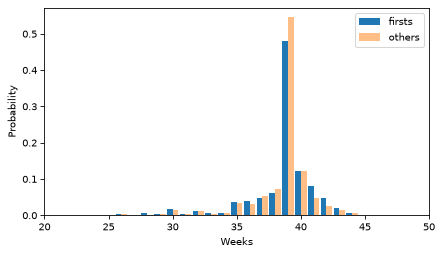

In [41]:
two_bar_plots(first_pmf, others_pmf)
decorate(xlabel="Weeks", ylabel="Probability", xlim=[20, 50])

In [42]:
weeks = range(35, 46)
first_pmf(weeks)

array([0.03602991, 0.03897575, 0.04713347, 0.06163608, 0.4790392 ,
       0.12145932, 0.08157716, 0.04645366, 0.01971448, 0.00521187,
       0.00135962])

In [44]:
others_pmf(weeks)

array([0.03210137, 0.03146779, 0.05216473, 0.07074974, 0.54466737,
       0.12249208, 0.04794087, 0.02597677, 0.01288279, 0.00485744,
       0.00084477])

In [45]:
diffs = first_pmf(weeks) - others_pmf(weeks)
diffs

array([ 0.00392854,  0.00750796, -0.00503126, -0.00911366, -0.06562817,
       -0.00103276,  0.03363629,  0.02047689,  0.00683169,  0.00035443,
        0.00051485])

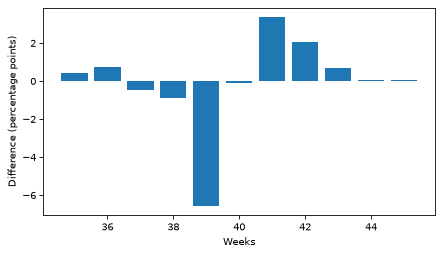

In [47]:
plt.bar(weeks, diffs*100)
decorate(xlabel = 'Weeks', ylabel = 'Difference (percentage points)')

In [48]:
#EXERCISE 3.1
from nsfg import read_fem_resp

resp = read_fem_resp()
resp.shape

/home/axiuc-fedor/think-stats/notebooks/nsfg.py:191: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  resp["agemarry"] = (resp.cmmarrhx - resp.cmbirth) / 12.0
/home/axiuc-fedor/think-stats/notebooks/nsfg.py:192: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  resp["age"] = (resp.cmintvw - resp.cmbirth) / 12.0
/home/axiuc-fedor/think-stats/notebooks/nsfg.py:195: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

(7643, 3092)

In [ ]:
number_of_babies = resp['numbabes']
babies_ftab = FreqTab.from_seq(number_of_babies)
babies_ftab


,freqs
numbabes,
0,3229
1,1519
2,1603
3,828
4,309
5,95
6,29
7,15
8,8


In [53]:
resp['numbabes'] = resp['numbabes'].replace([97], np.nan)
babies_ftab = FreqTab.from_seq(resp['numbabes'])
babies_ftab

,freqs
numbabes,
0.0,3229
1.0,1519
2.0,1603
3.0,828
4.0,309
5.0,95
6.0,29
7.0,15
8.0,8


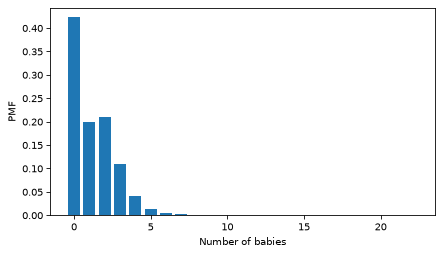

In [ ]:
pmf = Pmf.from_seq(resp['numbabes'])
pmf.bar()
decorate(xlabel='Number of babies', ylabel='PMF')
#The distribution is not symmetric, it is skewed to the right